# LSTM Training for Dynamic Gesture Recognition (ViT Features)

This notebook demonstrates how to train an LSTM model for dynamic gesture recognition using features extracted from your fine-tuned ViT (located at `checkpoints/best_model.pth`). The dataset is organized as follows:
- `dataset/Train/`, `dataset/Validation/`, `dataset/Test/`: Folders with per-video subfolders containing frames as JPEGs.
- `dataset/Train.csv`, `dataset/Validation.csv`, `dataset/Test.csv`: CSVs mapping video IDs to gesture labels and metadata.

The LSTM is trained on features extracted from video frame sequences using your ViT.

## 1. Import Required Libraries

In [2]:
import os
import numpy as np
import pandas as pd
import torch
from torchvision import transforms
from PIL import Image
from tqdm import tqdm
from sklearn.preprocessing import LabelEncoder
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.utils import to_categorical
import torch
import torch.nn as nn
import timm

## 2. Dataset Preparation: CSV and Directory Structure
- Each row in the CSV corresponds to a video.
- Each video has a folder in `dataset/Train/` (or Validation/Test) named by its video_id, containing frames as JPEGs.
- We'll load the CSV, sample frames, and extract features for each video.

In [3]:
DATASET_ROOT = '../dataset' 
TRAIN_CSV = os.path.join(DATASET_ROOT, 'Train.csv')
VAL_CSV = os.path.join(DATASET_ROOT, 'Validation.csv')
TRAIN_DIR = os.path.join(DATASET_ROOT, 'Train')
VAL_DIR = os.path.join(DATASET_ROOT, 'Validation')

# Read CSVs
train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
print(f'Train samples: {len(train_df)}, Validation samples: {len(val_df)}')

Train samples: 50420, Validation samples: 7047


## 3. Label Encoding
Encode gesture labels as integers for training.

In [39]:
le = LabelEncoder()
all_labels = pd.concat([train_df['label'], val_df['label']])
le.fit(all_labels)
num_classes = len(le.classes_)
print('Classes:', list(le.classes_))

Classes: ['Doing other things', 'Drumming Fingers', 'No gesture', 'Pulling Hand In', 'Pulling Two Fingers In', 'Pushing Hand Away', 'Pushing Two Fingers Away', 'Rolling Hand Backward', 'Rolling Hand Forward', 'Shaking Hand', 'Sliding Two Fingers Down', 'Sliding Two Fingers Left', 'Sliding Two Fingers Right', 'Sliding Two Fingers Up', 'Stop Sign', 'Swiping Down', 'Swiping Left', 'Swiping Right', 'Swiping Up', 'Thumb Down', 'Thumb Up', 'Turning Hand Clockwise', 'Turning Hand Counterclockwise', 'Zooming In With Full Hand', 'Zooming In With Two Fingers', 'Zooming Out With Full Hand', 'Zooming Out With Two Fingers']


## ViT Feature Extractor

This cell defines a Vision Transformer (ViT) feature extractor directly in the notebook to avoid external imports. The model loads a fine-tuned checkpoint, removes the classification head, and outputs fixed-length feature embeddings for each video frame.

In [40]:
class ViTFeatureExtractor(nn.Module):
    def __init__(self, checkpoint_path, device, checkpoint_num_classes=23):
        super().__init__()
        self.device = device

        # Create ViT model with the same number of classes as the checkpoint
        self.vit = timm.create_model(
            "vit_base_patch16_224",
            pretrained=False,
            num_classes=checkpoint_num_classes
        )

        # Load checkpoint
        checkpoint = torch.load(checkpoint_path, map_location=device)
        if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
            self.vit.load_state_dict(checkpoint["model_state_dict"])
        else:
            self.vit.load_state_dict(checkpoint)

        # Remove classification head → feature extractor
        self.vit.reset_classifier(0)

        # Freeze ViT
        for p in self.vit.parameters():
            p.requires_grad = False

        self.vit.to(device)
        self.vit.eval()

    def forward(self, x):
        with torch.no_grad():
            return self.vit(x)


## 4. ViT Feature Extractor Setup
Use your fine-tuned ViT for per-frame feature extraction.

In [41]:
# Set device and checkpoint path
vit_checkpoint = '../checkpoints/best_model.pth'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
num_classes = len(le.classes_)

# Initialize ViT feature extractor
vit_extractor = ViTFeatureExtractor(
    vit_checkpoint,
    device,
    checkpoint_num_classes=23  # number of classes in the checkpoint
)

# Define preprocessing for ViT
vit_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

def extract_vit_feature(img_path):
    img = Image.open(img_path).convert('RGB')
    img_tensor = vit_transform(img).unsqueeze(0).to(device)  # (1, 3, 224, 224)
    feat = vit_extractor(img_tensor).cpu().numpy().squeeze()  # (768,)
    return feat

feature_dim = 768

/tmp/ipykernel_463396/1113146856.py:14: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(checkpoint_path, map_location=device)


## 5. Sequence Loader: Build X, y for LSTM
For each video, load all frames, extract features, and build a sequence. Pad/truncate to SEQ_LEN.

In [42]:
SEQ_LEN = 37  # As in CSV

def load_video_sequence(video_id, folder, seq_len=SEQ_LEN):
    video_folder = os.path.join(folder, str(video_id))
    frame_files = sorted([f for f in os.listdir(video_folder) if f.endswith('.jpg') or f.endswith('.jpeg')])
    # Sort numerically (e.g., 00001.jpg)
    frame_files = sorted(frame_files, key=lambda x: int(os.path.splitext(x)[0]))
    frames = []
    for i in range(seq_len):
        if i < len(frame_files):
            frame_path = os.path.join(video_folder, frame_files[i])
            feat = extract_vit_feature(frame_path)
        else:
            feat = np.zeros(feature_dim)
        frames.append(feat)
    return np.stack(frames)

def build_dataset(df, folder):
    X, y = [], []
    for idx, row in tqdm(df.iterrows(), total=len(df)):
        video_id = row['video_id']
        label = row['label']
        seq = load_video_sequence(video_id, folder)
        X.append(seq)
        y.append(le.transform([label])[0])
    return np.array(X), to_categorical(y, num_classes=num_classes)

## 6. Load Train/Validation Sets from Disk

Instead of building the dataset, we load the pre-extracted features and labels from .npy files.

In [43]:
# Load pre-extracted features and labels from .npy files
X_train = np.load('../dataset/X_train.npy')
y_train = np.load('../dataset/y_train.npy')
X_val = np.load('../dataset/X_val.npy')
y_val = np.load('../dataset/y_val.npy')
print('Train:', X_train.shape, y_train.shape)
print('Val:', X_val.shape, y_val.shape)

Train: (50420, 37, 768) (50420, 27)
Val: (7047, 37, 768) (7047, 27)


In [ ]:
# In case U didn't have them pre-extracted, un-comment the following code: 
# X_train, y_train = build_dataset(train_df, TRAIN_DIR)
# X_val, y_val = build_dataset(val_df, VAL_DIR)

# Inspect resulting shapes
# print("Train:", X_train.shape, y_train.shape)
# print("Val:", X_val.shape, y_val.shape)

## 7. Build the LSTM Model

### Improved LSTM Model: Bidirectional, More Units, Regularization

We use Bidirectional LSTM layers, increase the number of units, and add more dropout for regularization.

In [44]:
from tensorflow.keras.layers import Bidirectional

def build_lstm_model(input_shape, num_classes):
    model = models.Sequential([
        layers.Masking(mask_value=0., input_shape=input_shape),
        Bidirectional(layers.LSTM(256, return_sequences=True)),
        layers.Dropout(0.4),
        Bidirectional(layers.LSTM(128)),
        layers.Dropout(0.4),
        layers.Dense(128, activation='relu', kernel_regularizer=keras.regularizers.l2(1e-4)),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

input_shape = (SEQ_LEN, feature_dim)
model = build_lstm_model(input_shape, num_classes)
model.summary()

/home/rachel/anaconda3/envs/gesture/lib/python3.10/site-packages/keras/src/layers/core/masking.py:48: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ masking_5 (Masking)             │ (None, 37, 768)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_4 (Bidirectional) │ (None, 37, 512)        │     2,099,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 37, 512)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_5 (Bidirectional) │ (None, 256)            │       656,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 27)             │         3,483 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,791,963 (10.65 MB)

 Trainable params: 2,791,963 (10.65 MB)

 Non-trainable params: 0 (0.00 B)

In [45]:
def build_lstm_model(input_shape, num_classes):
    model = models.Sequential([
        layers.Masking(mask_value=0., input_shape=input_shape),
        layers.LSTM(128, return_sequences=True),
        layers.Dropout(0.3),
        layers.LSTM(64),
        layers.Dropout(0.3),
        layers.Dense(64, activation='relu'),
        layers.Dense(num_classes, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

input_shape = (SEQ_LEN, feature_dim)
model = build_lstm_model(input_shape, num_classes)
model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ masking_6 (Masking)             │ (None, 37, 768)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_12 (LSTM)                  │ (None, 37, 128)        │       459,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 37, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_13 (LSTM)                  │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 27)             │         1,755 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 514,587 (1.96 MB)

 Trainable params: 514,587 (1.96 MB)

 Non-trainable params: 0 (0.00 B)

## 8. Train the LSTM Model with Model Checkpointing

### Learning Rate Scheduling and Early Stopping

We add ReduceLROnPlateau to reduce the learning rate on plateaus and EarlyStopping to prevent overfitting.

In [46]:
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1)
early_stop = EarlyStopping(monitor='val_accuracy', patience=7, restore_best_weights=True, verbose=1)

In [47]:
BEST_MODEL_PATH = './best_lstm_model.h5'
checkpoint = ModelCheckpoint(BEST_MODEL_PATH, monitor='val_accuracy', save_best_only=True, mode='max', verbose=1)
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=8,
    callbacks=[checkpoint, reduce_lr, early_stop],  # learning rate scheduler and early stopping
    verbose=1
)

Epoch 1/30
6302/6303 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.3484 - loss: 2.1910
Epoch 1: val_accuracy improved from None to 0.57713, saving model to ./best_lstm_model.h5


6303/6303 ━━━━━━━━━━━━━━━━━━━━ 133s 21ms/step - accuracy: 0.4486 - loss: 1.8217 - val_accuracy: 0.5771 - val_loss: 1.4101 - learning_rate: 0.0010
Epoch 2/30
6303/6303 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.5774 - loss: 1.3765
Epoch 2: val_accuracy improved from 0.57713 to 0.63460, saving model to ./best_lstm_model.h5


6303/6303 ━━━━━━━━━━━━━━━━━━━━ 129s 20ms/step - accuracy: 0.5943 - loss: 1.3235 - val_accuracy: 0.6346 - val_loss: 1.2167 - learning_rate: 0.0010
Epoch 3/30
6301/6303 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6379 - loss: 1.1714
Epoch 3: val_accuracy improved from 0.63460 to 0.67759, saving model to ./best_lstm_model.h5


6303/6303 ━━━━━━━━━━━━━━━━━━━━ 128s 20ms/step - accuracy: 0.6429 - loss: 1.1572 - val_accuracy: 0.6776 - val_loss: 1.0540 - learning_rate: 0.0010
Epoch 4/30
6303/6303 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6744 - loss: 1.0611
Epoch 4: val_accuracy improved from 0.67759 to 0.69107, saving model to ./best_lstm_model.h5


6303/6303 ━━━━━━━━━━━━━━━━━━━━ 129s 20ms/step - accuracy: 0.6754 - loss: 1.0563 - val_accuracy: 0.6911 - val_loss: 1.0148 - learning_rate: 0.0010
Epoch 5/30
6303/6303 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6947 - loss: 1.0002
Epoch 5: val_accuracy improved from 0.69107 to 0.70626, saving model to ./best_lstm_model.h5


...

6303/6303 ━━━━━━━━━━━━━━━━━━━━ 128s 20ms/step - accuracy: 0.7907 - loss: 0.6917 - val_accuracy: 0.7788 - val_loss: 0.7593 - learning_rate: 0.0010
Epoch 19/30
6301/6303 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.7991 - loss: 0.6750
Epoch 19: val_accuracy did not improve from 0.77877
6303/6303 ━━━━━━━━━━━━━━━━━━━━ 129s 20ms/step - accuracy: 0.7976 - loss: 0.6792 - val_accuracy: 0.7747 - val_loss: 0.7655 - learning_rate: 0.0010
Epoch 20/30
6302/6303 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8007 - loss: 0.6672
Epoch 20: val_accuracy did not improve from 0.77877
6303/6303 ━━━━━━━━━━━━━━━━━━━━ 129s 20ms/step - accuracy: 0.7989 - loss: 0.6747 - val_accuracy: 0.7724 - val_loss: 0.7729 - learning_rate: 0.0010
Epoch 21/30
6302/6303 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8026 - loss: 0.6581
Epoch 21: val_accuracy did not improve from 0.77877
6303/6303 ━━━━━━━━━━━━━━━━━━━━ 129s 21ms/step - accuracy: 0.7993 - loss: 0.6676 - val_accuracy: 0.7772 - val_loss: 0.7504 - learning_rat

6303/6303 ━━━━━━━━━━━━━━━━━━━━ 128s 20ms/step - accuracy: 0.8021 - loss: 0.6579 - val_accuracy: 0.7818 - val_loss: 0.7384 - learning_rate: 0.0010
Epoch 23/30
6302/6303 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8091 - loss: 0.6359
Epoch 23: val_accuracy did not improve from 0.78175
6303/6303 ━━━━━━━━━━━━━━━━━━━━ 128s 20ms/step - accuracy: 0.8055 - loss: 0.6447 - val_accuracy: 0.7798 - val_loss: 0.7526 - learning_rate: 0.0010
Epoch 24/30
6301/6303 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8110 - loss: 0.6247
Epoch 24: val_accuracy improved from 0.78175 to 0.78402, saving model to ./best_lstm_model.h5


6303/6303 ━━━━━━━━━━━━━━━━━━━━ 128s 20ms/step - accuracy: 0.8074 - loss: 0.6407 - val_accuracy: 0.7840 - val_loss: 0.7291 - learning_rate: 0.0010
Epoch 25/30
6300/6303 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8118 - loss: 0.6186
Epoch 25: val_accuracy improved from 0.78402 to 0.78828, saving model to ./best_lstm_model.h5


6303/6303 ━━━━━━━━━━━━━━━━━━━━ 130s 21ms/step - accuracy: 0.8077 - loss: 0.6352 - val_accuracy: 0.7883 - val_loss: 0.7478 - learning_rate: 0.0010
Epoch 26/30
6300/6303 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8127 - loss: 0.6231
Epoch 26: val_accuracy did not improve from 0.78828
6303/6303 ━━━━━━━━━━━━━━━━━━━━ 131s 21ms/step - accuracy: 0.8089 - loss: 0.6359 - val_accuracy: 0.7874 - val_loss: 0.7325 - learning_rate: 0.0010
Epoch 27/30
6302/6303 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8203 - loss: 0.5930
Epoch 27: val_accuracy improved from 0.78828 to 0.79140, saving model to ./best_lstm_model.h5


6303/6303 ━━━━━━━━━━━━━━━━━━━━ 128s 20ms/step - accuracy: 0.8153 - loss: 0.6132 - val_accuracy: 0.7914 - val_loss: 0.7035 - learning_rate: 0.0010
Epoch 28/30
6303/6303 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8177 - loss: 0.6077
Epoch 28: val_accuracy did not improve from 0.79140
6303/6303 ━━━━━━━━━━━━━━━━━━━━ 129s 20ms/step - accuracy: 0.8180 - loss: 0.6109 - val_accuracy: 0.7859 - val_loss: 0.7512 - learning_rate: 0.0010
Epoch 29/30
6302/6303 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8175 - loss: 0.6018
Epoch 29: val_accuracy did not improve from 0.79140
6303/6303 ━━━━━━━━━━━━━━━━━━━━ 128s 20ms/step - accuracy: 0.8148 - loss: 0.6100 - val_accuracy: 0.7901 - val_loss: 0.7265 - learning_rate: 0.0010
Epoch 30/30
6302/6303 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8176 - loss: 0.5915
Epoch 30: val_accuracy did not improve from 0.79140

Epoch 30: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
6303/6303 ━━━━━━━━━━━━━━━━━━━━ 127s 20ms/step - accuracy: 

## 9. Evaluate Model Performance

In [48]:
best_model = keras.models.load_model(BEST_MODEL_PATH)
val_loss, val_acc = best_model.evaluate(X_val, y_val, verbose=1)
print(f'Validation Loss: {val_loss:.4f}')
print(f'Validation Accuracy: {val_acc:.4f}')

221/221 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - accuracy: 0.7914 - loss: 0.7035
Validation Loss: 0.7035
Validation Accuracy: 0.7914


## 11. Visualize Training History and Model Performance

Visualize training/validation accuracy and loss, and analyze the confusion matrix and classification report to see where the model performed well or poorly.

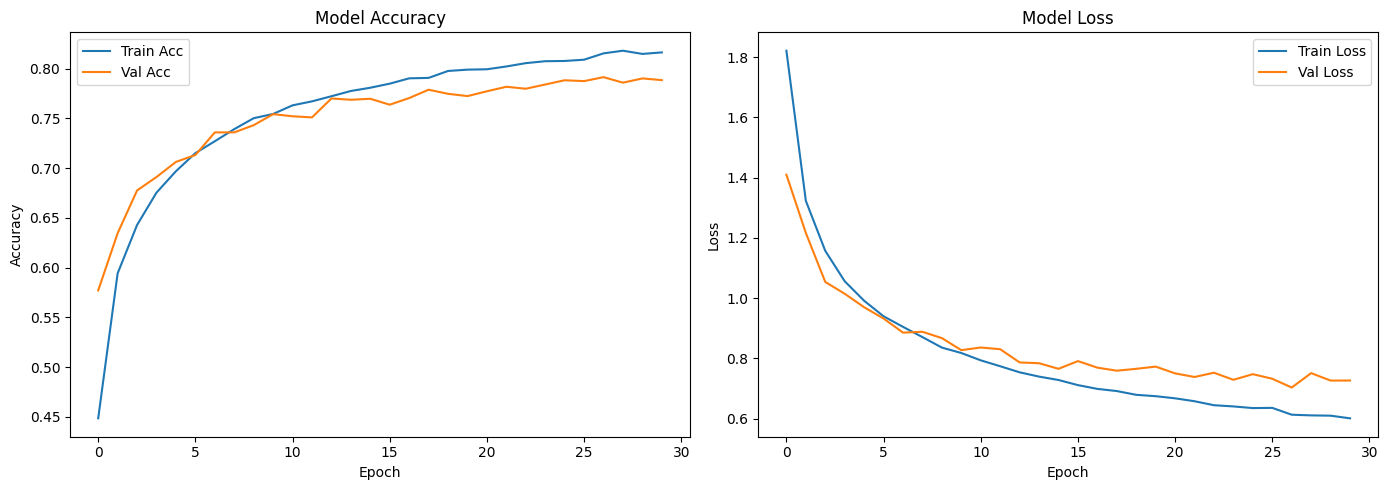

221/221 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step
Classification Report:
                               precision    recall  f1-score   support

           Doing other things       0.67      0.80      0.73       713
             Drumming Fingers       0.88      0.85      0.87       257
                   No gesture       0.81      0.93      0.87       256
              Pulling Hand In       0.72      0.70      0.71       250
       Pulling Two Fingers In       0.75      0.71      0.73       233
            Pushing Hand Away       0.82      0.85      0.84       246
     Pushing Two Fingers Away       0.71      0.80      0.75       241
        Rolling Hand Backward       0.86      0.76      0.80       239
         Rolling Hand Forward       0.81      0.86      0.84       244
                 Shaking Hand       0.87      0.84      0.85       245
     Sliding Two Fingers Down       0.76      0.82      0.79       249
     Sliding Two Fingers Left       0.78      0.76      0.77       246
    Sliding

In [49]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Plot training & validation accuracy/loss
plt.figure(figsize=(14,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

# Predict on validation set
val_preds = best_model.predict(X_val, batch_size=32)
y_true = y_val.argmax(axis=1)
y_pred = val_preds.argmax(axis=1)

# Classification report
print('Classification Report:')
print(classification_report(y_true, y_pred, target_names=list(le.classes_)))

## 10. Save the Best LSTM Model

In [50]:
FINAL_MODEL_PATH = './final_lstm_model79.h5'
best_model.save(FINAL_MODEL_PATH)
print(f'Best LSTM model saved to {FINAL_MODEL_PATH}')

Best LSTM model saved to ./final_lstm_model79.h5
